# 5. Dense projections (PCA / truncated SVD) and kernel SVMs

**Questions:**
1. Does projecting the sparse TF-IDF space onto its top-k orthogonal directions of variance
   (PCA-style) and then fitting logistic regression generalise better than coordinate-wise
   selection by Lasso?
2. Does a Gaussian RBF kernel, which can model interactions between rhetorical terms,
   beat the linear margin?

*Why truncated SVD instead of `sklearn.decomposition.PCA`?* PCA centres the data, which turns
the 14,341 × ~38k sparse matrix into a dense one (~4 GB). Truncated SVD computes the same
kind of low-rank projection without centring. The SVD basis and the standardisation are fitted
inside a pipeline on `train` only.

*Why the RBF SVM runs on a 300-d SVD projection:* the kernel SVM needs pairwise kernel
evaluations (O(n²) per label × 16 labels); on the raw sparse space this was impractical on a
laptop. This is a stated compromise, not a claim that 300 dimensions are optimal.

As in notebook 04, the test split is not loaded.

In [1]:
import sys, json, time, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.config import RESULTS, FIGURES
from src.data import load_dataset, get_splits
from src.features import word_tfidf
from src.models import pca_logreg, svd_rbf_svm, linear_svm, scores_of
from src.evaluate import scores

df, LABELS = load_dataset()
S = get_splits(df, LABELS)
X_tr, Y_tr, _ = S["train"]; X_va, Y_va, _ = S["val"]; del S["test"]
vec = word_tfidf(ngram_range=(1, 2))           # representation selected in notebook 04
A = vec.fit_transform(X_tr); B = vec.transform(X_va)
A.shape

(14341, 38246)

## 5.1 How much variance do the leading components capture?

k=   50:  12.7% of TF-IDF variance
k=  100:  17.7% of TF-IDF variance
k=  300:  29.4% of TF-IDF variance
k= 1000:  48.5% of TF-IDF variance


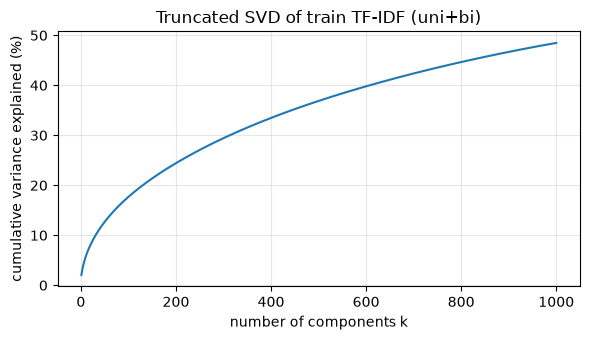

In [2]:
from sklearn.decomposition import TruncatedSVD
svd = TruncatedSVD(n_components=1000, random_state=42).fit(A)
cum = np.cumsum(svd.explained_variance_ratio_)
for k in [50, 100, 300, 1000]:
    print(f"k={k:5d}: {cum[k-1]*100:5.1f}% of TF-IDF variance")
plt.figure(figsize=(6, 3.5)); plt.plot(np.arange(1, 1001), cum * 100)
plt.xlabel("number of components k"); plt.ylabel("cumulative variance explained (%)")
plt.title("Truncated SVD of train TF-IDF (uni+bi)"); plt.grid(alpha=.3); plt.tight_layout()
plt.savefig(FIGURES / "svd_variance.png", dpi=150); plt.show()

The spectrum is flat: even 1,000 directions keep well under the full variance. Text TF-IDF
has no small set of dominant directions, so a dense projection necessarily discards many
rare-but-informative n-grams. This is the prediction we test below.

In [3]:
rows = []
for k in [50, 100, 300, 1000]:
    for cw in [None, "balanced"]:
        t = time.time(); m = pca_logreg(k=k, C=1.0, class_weight=cw).fit(A, Y_tr)
        p = m.predict(B)
        rows.append({"model": f"SVD-{k} + LR cw={cw}", "family": "PCA-LR", "k": k,
                     "class_weight": str(cw), "C": 1.0, **scores(Y_va, p, scores_of(m, B)),
                     "fit_seconds": round(time.time() - t, 1)})
        print(rows[-1]["model"], round(rows[-1]["macro_f1"], 4), rows[-1]["fit_seconds"], "s")

SVD-50 + LR cw=None 0.553 1.3 s


SVD-50 + LR cw=balanced 0.4569 1.6 s


SVD-100 + LR cw=None 0.6219 2.5 s


SVD-100 + LR cw=balanced 0.5197 2.5 s


SVD-300 + LR cw=None 0.7194 18.1 s


SVD-300 + LR cw=balanced 0.6288 21.0 s


SVD-1000 + LR cw=None 0.7686 70.6 s


SVD-1000 + LR cw=balanced 0.7274 57.2 s


## 5.2 RBF-kernel SVM
$K(x, x') = \exp(-\gamma\|x-x'\|^2)$ with `gamma="scale"`. Inputs are unit-normalised SVD
projections. We also record the number of **support vectors**: the training arguments that
lie on or inside the margin and therefore define the boundary.

In [4]:
for C in [1, 10]:
    for cw in [None, "balanced"]:
        t = time.time(); m = svd_rbf_svm(C=C, class_weight=cw, k=300).fit(A, Y_tr)
        p = m.predict(B)
        n_sv = [int(e.n_support_.sum()) for e in m[-1].estimators_]
        rows.append({"model": f"SVD-300 + RBF-SVM C={C} cw={cw}", "family": "RBF-SVM", "k": 300,
                     "class_weight": str(cw), "C": C, **scores(Y_va, p, scores_of(m, B)),
                     "mean_support_vectors": float(np.mean(n_sv)),
                     "fit_seconds": round(time.time() - t, 1)})
        print(rows[-1]["model"], round(rows[-1]["macro_f1"], 4), "mean #SV/label:",
              int(np.mean(n_sv)), rows[-1]["fit_seconds"], "s")

SVD-300 + RBF-SVM C=1 cw=None 0.6316 mean #SV/label: 1974 85.5 s


SVD-300 + RBF-SVM C=1 cw=balanced 0.7525 mean #SV/label: 2865 80.2 s


SVD-300 + RBF-SVM C=10 cw=None 0.7873 mean #SV/label: 2401 77.1 s


SVD-300 + RBF-SVM C=10 cw=balanced 0.7894 mean #SV/label: 2395 67.7 s


Control: the **linear** SVM on the *same* 300-d projection isolates the effect of the kernel
from the effect of the projection.

In [5]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import Normalizer
for cw in [None, "balanced"]:
    m = make_pipeline(TruncatedSVD(300, random_state=42), Normalizer(), linear_svm(1.0, cw)).fit(A, Y_tr)
    p = m.predict(B)
    rows.append({"model": f"SVD-300 + Linear-SVM cw={cw}", "family": "SVD-LinearSVM", "k": 300,
                 "class_weight": str(cw), "C": 1.0, **scores(Y_va, p, scores_of(m, B))})
    print(rows[-1]["model"], round(rows[-1]["macro_f1"], 4))

SVD-300 + Linear-SVM cw=None 0.6762


SVD-300 + Linear-SVM cw=balanced 0.6143


In [6]:
res = pd.DataFrame(rows)
res.to_csv(RESULTS / "val_grid_dense.csv", index=False)
lin = pd.read_csv(RESULTS / "val_grid_linear.csv")
ref = lin[lin.model.isin(["Unigram BoW + LR (nb03)"])]
best_sparse = lin[lin.family != "baseline"].sort_values("macro_f1", ascending=False).head(1)
cmp = pd.concat([ref, best_sparse, res.sort_values("macro_f1", ascending=False)])
cmp[["model", "macro_f1", "micro_f1", "macro_avg_precision"]].round(4)

,model,macro_f1,micro_f1,macro_avg_precision
2,Unigram BoW + LR (nb03),0.7641,0.7974,0.8368
52,TF-IDF uni+bi LinearSVM C=1 cw=balanced,0.8229,0.8335,0.8673
11,SVD-300 + RBF-SVM C=10 cw=balanced,0.7894,0.8170,0.8192
10,SVD-300 + RBF-SVM C=10 cw=None,0.7873,0.8175,0.8262
6,SVD-1000 + LR cw=None,0.7686,0.7870,0.8168
9,SVD-300 + RBF-SVM C=1 cw=balanced,0.7525,0.8045,0.8048
7,SVD-1000 + LR cw=balanced,0.7274,0.7643,0.7990
4,SVD-300 + LR cw=None,0.7194,0.7915,0.7603
12,SVD-300 + Linear-SVM cw=None,0.6762,0.7974,0.7730
8,SVD-300 + RBF-SVM C=1 cw=None,0.6316,0.7994,0.8213


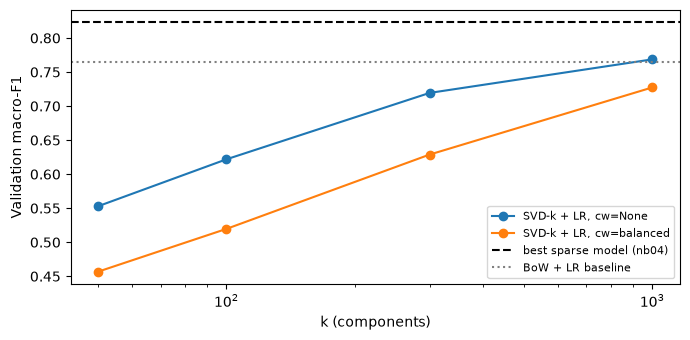

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.5))
pl = res[res.family == "PCA-LR"]
for cw, g in pl.groupby("class_weight"):
    ax.plot(g.k, g.macro_f1, marker="o", label=f"SVD-k + LR, cw={cw}")
ax.axhline(best_sparse.macro_f1.iloc[0], ls="--", c="k", label="best sparse model (nb04)")
ax.axhline(ref.macro_f1.iloc[0], ls=":", c="grey", label="BoW + LR baseline")
ax.set_xscale("log"); ax.set_xlabel("k (components)"); ax.set_ylabel("Validation macro-F1")
ax.legend(fontsize=8); plt.tight_layout(); plt.savefig(FIGURES / "svd_k_vs_f1.png", dpi=150); plt.show()

In [8]:
sel_path = RESULTS / "selection.json"; sel = json.loads(sel_path.read_text())
for fam in ["PCA-LR", "RBF-SVM"]:
    r = res[res.family == fam].sort_values("macro_f1", ascending=False).iloc[0]
    sel[fam] = {"model": r["model"], "k": int(r["k"]), "C": float(r["C"]),
                "class_weight": r["class_weight"], "macro_f1": float(r["macro_f1"])}
sel_path.write_text(json.dumps(sel, indent=2)); print(json.dumps({f: sel[f] for f in ["PCA-LR", "RBF-SVM"]}, indent=2))

{
  "PCA-LR": {
    "model": "SVD-1000 + LR cw=None",
    "k": 1000,
    "C": 1.0,
    "class_weight": "None",
    "macro_f1": 0.7686393230640249
  },
  "RBF-SVM": {
    "model": "SVD-300 + RBF-SVM C=10 cw=balanced",
    "k": 300,
    "C": 10.0,
    "class_weight": "balanced",
    "macro_f1": 0.7894359130522337
  }
}
